# LIBS Viewer: loading and inspecting data

How the files look once loaded: parameters, locations and shots, spectra and a first plot. For a full analysis see [quick_study.ipynb](quick_study.ipynb) (one call) or [end_to_end_temp_study.ipynb](end_to_end_temp_study.ipynb) (step by step).

Install the package into the kernel first (`pip install -e .` from the repository root). Paths are found relative to the repository root, so the notebook runs from either the root or `examples/`.

**How a file stores its shots**

Every stored spectrum is one TDMS channel named `Grid Location # L-S` (location L, shot S). What it holds depends on the *Accumulate* setting:

| Accumulate | one stored spectrum is | example |
|---|---|---|
| 1 | the sum of *Number Of Shots* shots at one location | `Gd_Sample1_300`: 2 spectra = 2 locations × 5 summed shots |
| 0 | a single shot; *Number Of Shots* spectra per location | `Ce1_300C`: 20 spectra = 2 locations × 10 single shots |

A file can mix both (`Gd_Sample5_300_3.5delay`, below).

**Data model**

- `LoadLIBSData(path)` loads one `.tdms` file or a whole folder, and behaves like a read-only dict `{file key: LIBSFile}`.
- Each `LIBSFile` holds:
  - `spectra`: raw counts; index = wavelength (nm), one column per stored spectrum
  - `acquisitions`: one row per stored spectrum, with `location`, `shot`, `shots_summed` (laser shots in it), X/Y/Z position and every instrument parameter
  - `params`: the instrument parameters of the first stored spectrum (normally the same for all)
  - `describe()`, `n_locations`, `storage`, `shots_per_location()`: quick summaries

## Load a folder

Every `.tdms` file in the folder (case-insensitive) is loaded; `recursive=True` includes subfolders. Keys are paths relative to the folder.

In [1]:
from pathlib import Path

import numpy as np

import libs_viewer.libs as LV
from libs_viewer.libs.plotting import plot_baseline, plot_spectrum

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
DATA = ROOT / 'data' / 'end_to_end'

libs = LV.LoadLIBSData(DATA, recursive=True)
print(len(libs), 'files')
list(libs.keys())

12 files


C:\Users\Jack\Desktop\Academic GitHub Repos\LIBS_Viewer\src\libs_viewer\libs\loading.py:374: SettingsWarning: Gd_Sample5_300_3.5delay.tdms: settings differ between stored spectra: ['Gate Delay (usec)', 'Accumulate', 'Energy', 'Number Of Shots', 'Rep Rate', 'Warmup Energy', '# Of Warmup Shots', 'Setpoint (2)'] (see varying_params())
  self.data[f.relative_to(root).as_posix()] = LIBSFile.from_tdms(f)


['Ce/1_wt%/Ce1 350 new location.tdms',
 'Ce/1_wt%/Ce1400.tdms',
 'Ce/1_wt%/Ce1_300C.tdms',
 'Ce/5_wt%/Ce_Sample2_Temp_300C.tdms',
 'Ce/5_wt%/Ce_Sample2_Temp_350C.tdms',
 'Ce/5_wt%/Ce_Sample2_Temp_400C.tdms',
 'Gd/1_wt%/Gd_Sample1_300.tdms',
 'Gd/1_wt%/Gd_Sample1_350.tdms',
 'Gd/1_wt%/Gd_Sample1_400.tdms',
 'Gd/5_wt%/Gd_Sample5_300_3.5delay.tdms',
 'Gd/5_wt%/Gd_Sample5_350_3.5delay.tdms',
 'Gd/5_wt%/Gd_Sample5_400_3.5delay.tdms']

## Compare files at a glance

`overview()` gives one row per file: locations, stored spectra, shots per location, how they were stored, and the settings that matter for a fair comparison. *mixed settings* lists parameters that differ between a file's own stored spectra.

In [2]:
libs.overview()

,locations,spectra,shots per location,stored as,energy (mJ),gate delay (us),mixed settings
file,,,,,,,
Ce/1_wt%/Ce1 350 new location.tdms,2,20,10,single shots,80.0,1.0,
Ce/1_wt%/Ce1400.tdms,2,20,10,single shots,80.0,1.0,
Ce/1_wt%/Ce1_300C.tdms,2,20,10,single shots,80.0,1.0,
Ce/5_wt%/Ce_Sample2_Temp_300C.tdms,1,1,5,accumulated,80.0,3.5,
Ce/5_wt%/Ce_Sample2_Temp_350C.tdms,1,1,5,accumulated,80.0,3.5,
Ce/5_wt%/Ce_Sample2_Temp_400C.tdms,2,10,5,single shots,80.0,3.5,
Gd/1_wt%/Gd_Sample1_300.tdms,2,2,5,accumulated,80.0,2.5,
Gd/1_wt%/Gd_Sample1_350.tdms,1,1,5,accumulated,80.0,2.5,
Gd/1_wt%/Gd_Sample1_400.tdms,1,1,5,accumulated,80.0,2.5,


## Inspect one file

Index the loader by key to get a `LIBSFile`. `param_table()` returns the parameters as a table.

In [3]:
f = libs['Ce/5_wt%/Ce_Sample2_Temp_400C.tdms']
f.param_table()

,Value
Param,
Gate Delay (usec),3.5
Accumulate,0
Energy,80
Energy Format,0
Number Of Shots,5
Rep Rate,1
Warmup Energy,80
# Of Warmup Shots,50
Warmup Rep Rate,10


In [4]:
# Parameters are also available as numbers (repeated names get a (1), (2) suffix)
f.params['Energy'], f.params['Gate Delay (usec)'], f.params['Gas Type (1)']

(np.float64(80.0), np.float64(3.5), np.float64(2.0))

## Locations and shots

`acquisitions` says what every stored spectrum is. This file was recorded with Accumulate = 0, so each of its 10 spectra is one shot: 5 shots at each of 2 locations.

In [5]:
f.acquisitions[['location', 'shot', 'shots_summed', 'X Position', 'Y Position', 'Z Position']]

,location,shot,shots_summed,X Position,Y Position,Z Position
spectrum,,,,,,
Grid Location # 1-1,1,1,1.0,50.890640,46.723415,24.159492
Grid Location # 1-2,1,2,1.0,50.890640,46.723415,24.159492
Grid Location # 1-3,1,3,1.0,50.890640,46.723415,24.159492
Grid Location # 1-4,1,4,1.0,50.890640,46.723415,24.159492
Grid Location # 1-5,1,5,1.0,50.890640,46.723415,24.159492
Grid Location # 2-1,2,1,1.0,49.391838,47.224613,23.759493
Grid Location # 2-2,2,2,1.0,49.391838,47.224613,23.759493
Grid Location # 2-3,2,3,1.0,49.391838,47.224613,23.759493
Grid Location # 2-4,2,4,1.0,49.391838,47.224613,23.759493


In [6]:
print(f.describe())
f.shots_per_location()

2 locations x 5 shots (single shots)


location
1    5.0
2    5.0
Name: shots_summed, dtype: float64

In [7]:
# Spectra: wavelength (nm) index, one column per stored spectrum
print(f.spectra.shape, f.wavelengths[0], '-', f.wavelengths[-1], 'nm')
f.spectra.iloc[:5, :3]

(12288, 10) 186.567596 - 1049.74292 nm


,Grid Location # 1-1,Grid Location # 1-2,Grid Location # 1-3
wavelength_nm,,,
186.567596,572.424988,543.599976,533.375
186.638397,516.424988,496.600006,573.375
186.709167,495.424988,491.600006,543.375
186.779938,527.424988,490.600006,534.375
186.850708,516.424988,556.599976,549.375


## Three ways to use the shots

| you want | use | gives |
|---|---|---|
| every stored spectrum (here: every single shot) | `LV.per_shot_columns(f)` | one column per stored spectrum, counts per shot |
| one spectrum per location | `LV.location_spectra(f)`, or `f.accumulate()` | mean per shot per location; or a new `LIBSFile` with the shots of each location summed, as if recorded with Accumulate = 1 |
| one spectrum for the whole file | `LV.per_shot_spectrum(f)` | all counts ÷ all shots |

Everything is on the same counts-per-shot scale, so they agree with each other:

In [8]:
shots = LV.per_shot_columns(f)        # 10 single shots
locs = LV.location_spectra(f)         # 2 locations
acc = f.accumulate()                  # LIBSFile: 2 summed spectra, 5 shots each
mean = LV.per_shot_spectrum(f)

print(shots.shape, locs.shape, '|', acc.describe())
np.allclose(LV.per_shot_spectrum(acc), mean), np.allclose(LV.per_shot_columns(acc), locs)

(12288, 10) (12288, 2) | 2 locations x 5 shots (accumulated)


(True, True)

Accumulating only goes one way. An accumulated file has no single shots left to split, so `accumulate()` on it warns and returns the file unchanged:

In [9]:
libs['Ce/5_wt%/Ce_Sample2_Temp_300C.tdms'].accumulate().describe()

C:\Users\Jack\AppData\Local\Temp\ipykernel_24016\1244298588.py:1: LayoutWarning: Ce_Sample2_Temp_300C.tdms: already one spectrum per location (accumulated); nothing to accumulate
  libs['Ce/5_wt%/Ce_Sample2_Temp_300C.tdms'].accumulate().describe()


'1 location x 5 shots (accumulated)'

## Choosing spectra

`subset` returns the same file restricted to some locations or stored spectra. Everything downstream then only sees those:

In [10]:
print(f.subset(locations=[2]).describe())
print(f.subset(columns=['Grid Location # 1-1', 'Grid Location # 1-2']).describe())
LV.per_shot_spectrum(f.subset(locations=[2]))[:5]

1 location x 5 shots (single shots)
1 location x 2 shots (single shots)


array([562.17501221, 530.1750061 , 461.5749939 , 537.77501221,
       553.5750061 ])

## Loader warnings

There are two kinds, both subclasses of `UserWarning`:

- **`SettingsWarning`**: instrument settings differ between the stored spectra of one file (the Gd file below).
- **`LayoutWarning`**: the locations don't add up. Spectra named as one location were taken at different stage positions (locations are then taken from the positions instead), two locations sit at the same stage position, or a location holds several spectra of which some are already accumulated.

`run_study` copies layout warnings into its `notes`. None of the files here has a layout problem.

## A file with mixed settings

The loader warned about `Gd_Sample5_300_3.5delay.tdms`:

In [11]:
g = libs['Gd/5_wt%/Gd_Sample5_300_3.5delay.tdms']
print(g.describe())
g.acquisitions[['location', 'shot', 'shots_summed', 'Accumulate', 'Gate Delay (usec)', 'Energy']]

2 locations x 5-10 shots (mixed)


,location,shot,shots_summed,Accumulate,Gate Delay (usec),Energy
spectrum,,,,,,
Grid Location # 1-1,1,1,5.0,1.0,3.5,80.0
Grid Location # 2-1,2,1,1.0,0.0,1.0,10.0
Grid Location # 2-2,2,2,1.0,0.0,1.0,10.0
Grid Location # 2-3,2,3,1.0,0.0,1.0,10.0
Grid Location # 2-4,2,4,1.0,0.0,1.0,10.0
Grid Location # 2-5,2,5,1.0,0.0,1.0,10.0
Grid Location # 2-6,2,6,1.0,0.0,1.0,10.0
Grid Location # 2-7,2,7,1.0,0.0,1.0,10.0
Grid Location # 2-8,2,8,1.0,0.0,1.0,10.0


Location 1 is one spectrum of 5 accumulated shots at 3.5 µs and 80 mJ, like the rest of the Gd 5 wt% series. Location 2 is 10 single shots at 1.0 µs and 10 mJ, a different experiment. `run_study` keeps only location 1 and says so in its notes; by hand it is `g.subset(locations=[1])`. `varying_params()` lists just the parameters that differ:

In [12]:
g.varying_params()

spectrum,Grid Location # 1-1,Grid Location # 2-1,Grid Location # 2-2,Grid Location # 2-3,Grid Location # 2-4,Grid Location # 2-5,Grid Location # 2-6,Grid Location # 2-7,Grid Location # 2-8,Grid Location # 2-9,Grid Location # 2-10
Gate Delay (usec),3.5,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
Accumulate,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Energy,80.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0
Number Of Shots,5.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0
Rep Rate,1.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0
Warmup Energy,80.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
# Of Warmup Shots,25.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0
Setpoint (2),1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Look at a spectrum

`plot_spectrum` labels the strongest peaks and returns a matplotlib `Figure`. Save one with `fig.savefig('spectrum.png')`.

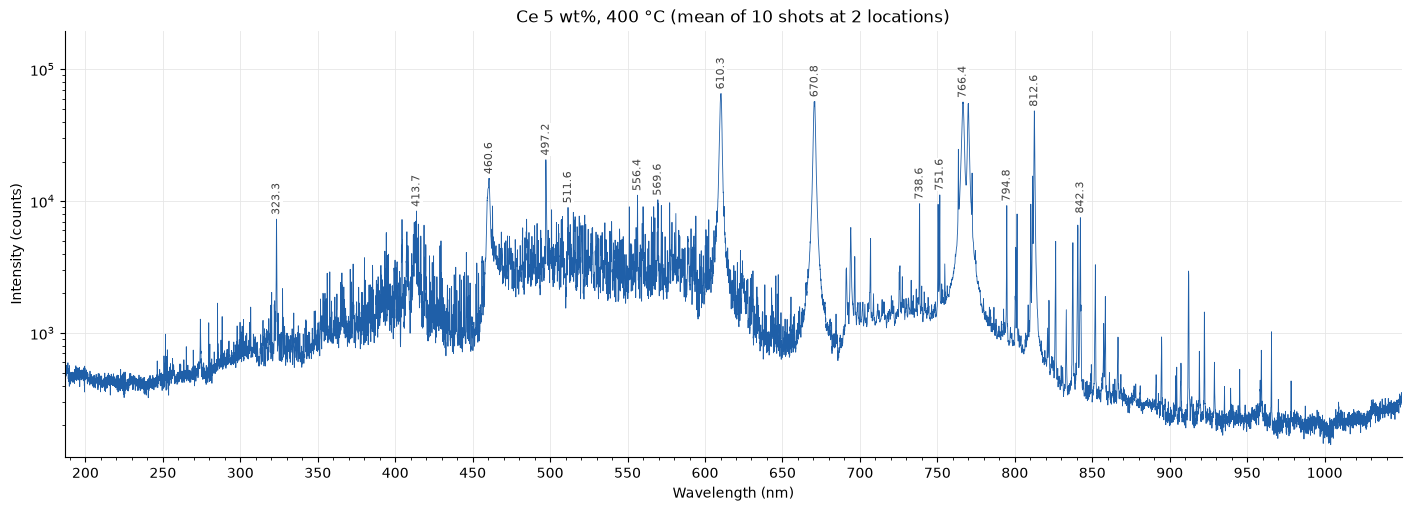

In [13]:
plot_spectrum(f.wavelengths, mean, title='Ce 5 wt%, 400 °C (mean of 10 shots at 2 locations)')

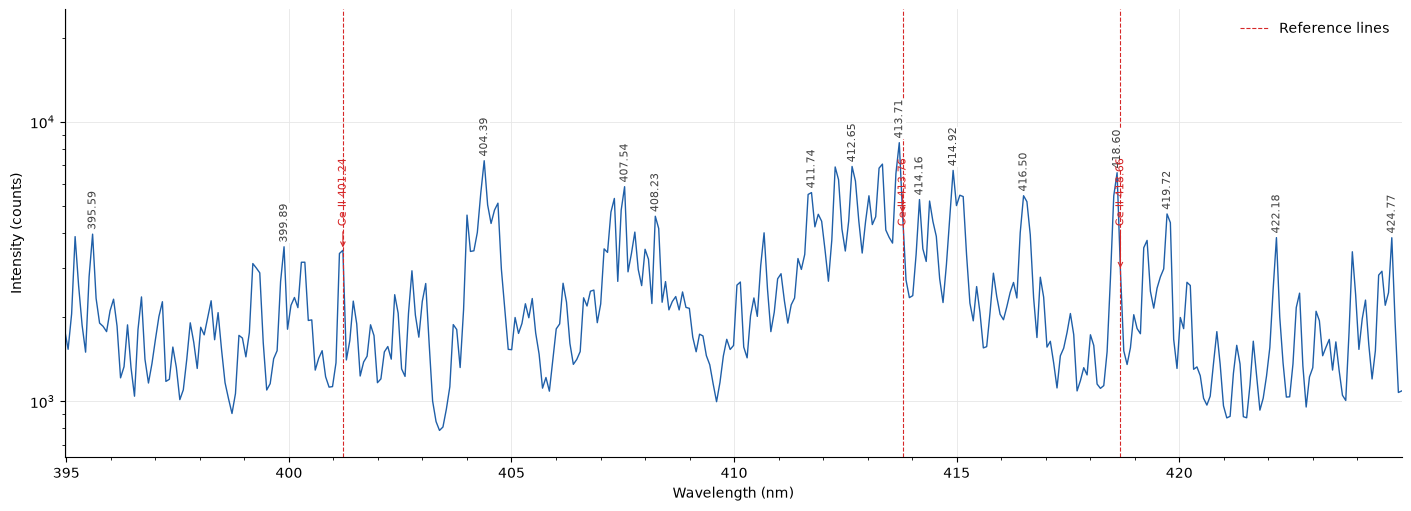

In [14]:
# zoom, with reference lines marked
plot_spectrum(f.wavelengths, mean, wl_range=(395, 425),
              ref_lines={'Ce II 418.66': 418.66, 'Ce II 413.76': 413.76, 'Ce II 401.24': 401.24})

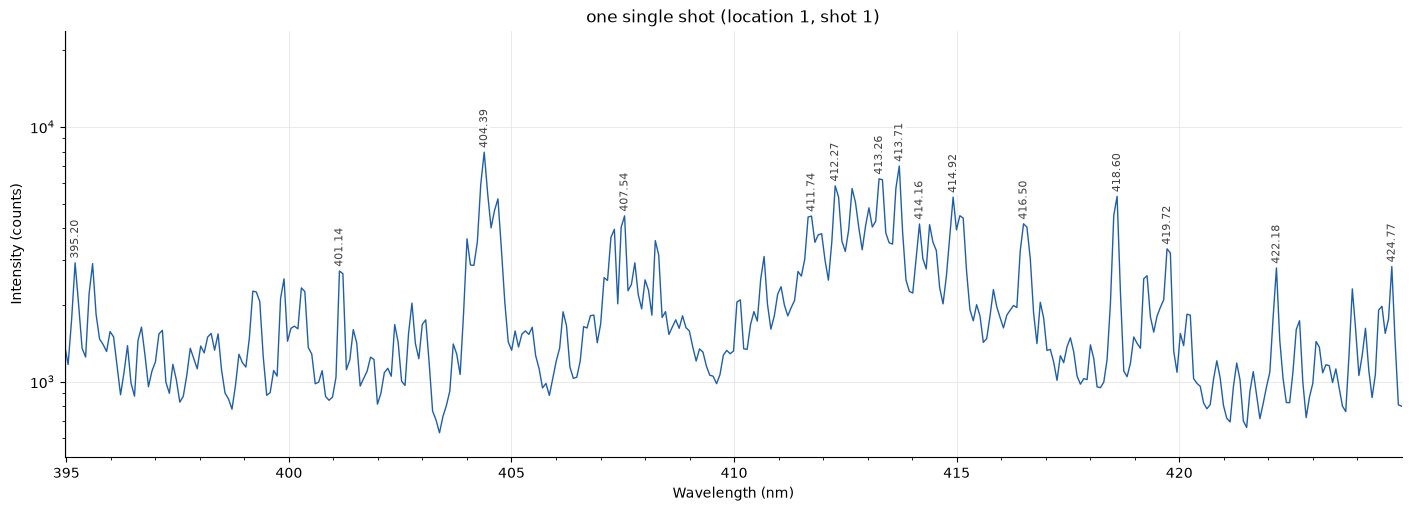

In [15]:
# a single shot is much noisier than the mean
plot_spectrum(f.wavelengths, shots['Grid Location # 1-1'].to_numpy(), wl_range=(395, 425),
              title='one single shot (location 1, shot 1)')

## Baseline (continuum) fit

`plot_baseline` shows the fitted continuum over the spectrum, and the corrected spectrum below it. Compare the two methods:

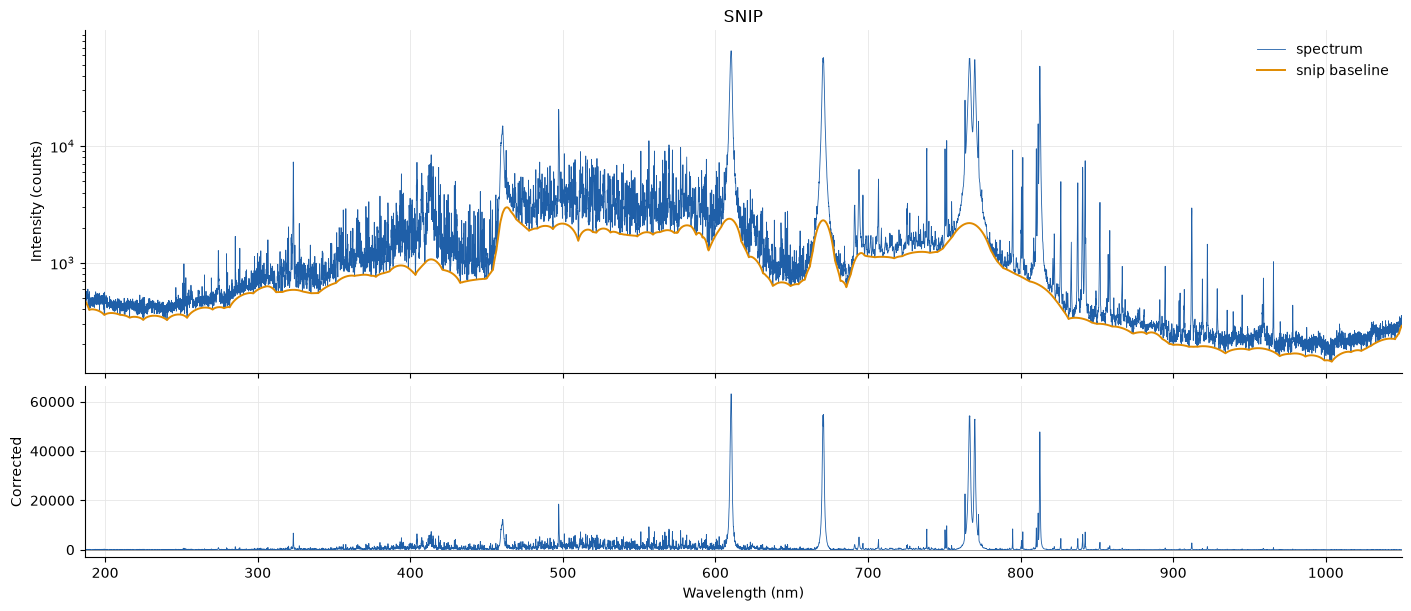

In [16]:
plot_baseline(f.wavelengths, mean, method='snip', title='SNIP')

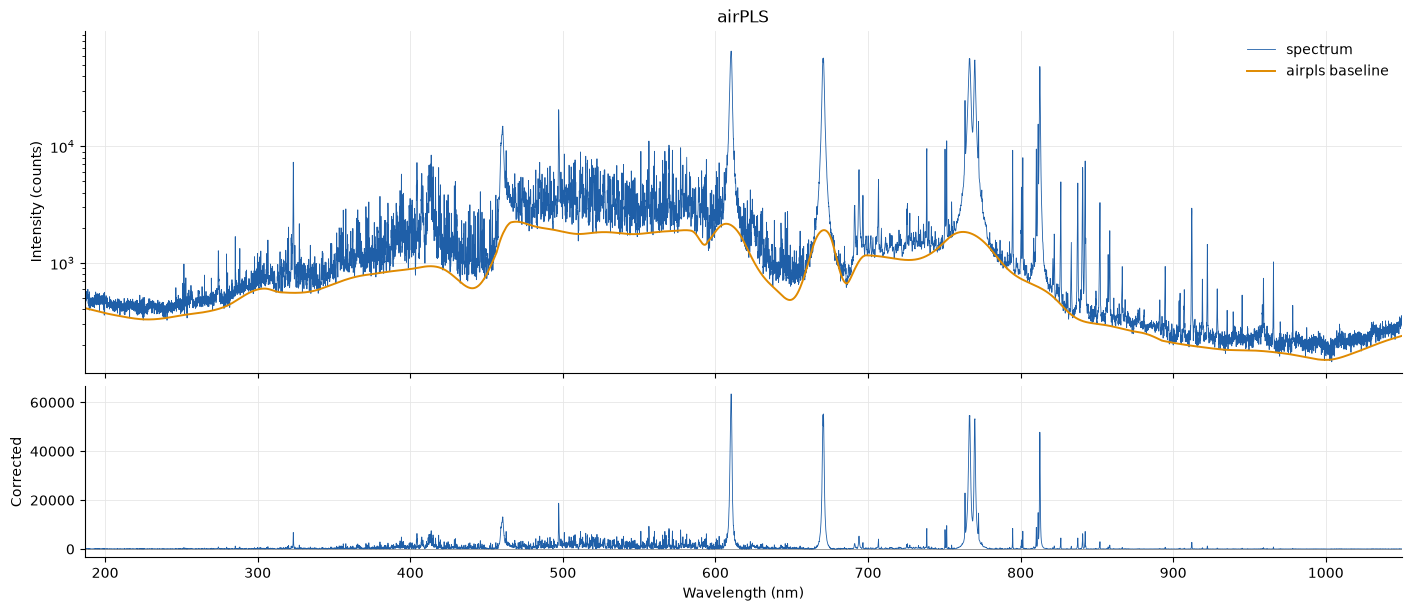

In [17]:
plot_baseline(f.wavelengths, mean, method='airpls', title='airPLS')

## Load a single file

A path to one `.tdms` file works too; the key is just the file name.

In [18]:
one = LV.LoadLIBSData(DATA / 'Ce' / '5_wt%' / 'Ce_Sample2_Temp_400C.tdms')
print(list(one.keys()))
one['Ce_Sample2_Temp_400C.tdms'].spectra.shape

['Ce_Sample2_Temp_400C.tdms']


(12288, 10)